# Sree Ram Roshan A S - 24BAD113

In [1]:
!pip install -q transformers datasets torch accelerate scikit-learn pandas matplotlib

In [2]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForSeq2SeqLM,
    TrainingArguments,
    Trainer,
    pipeline
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

ROLL_NO = "ENTER YOUR ROLL NUMBER"

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Student Roll Number:", ROLL_NO)
print("Device:", device)
print("PyTorch Version:", torch.__version__)

Student Roll Number: ENTER YOUR ROLL NUMBER
Device: cuda
PyTorch Version: 2.11.0+cu130


# Part A

In [4]:
dataset = load_dataset("stanfordnlp/imdb")

print("Dataset:", dataset)

print("Training samples:",
      len(dataset["train"]))

print("Testing samples:",
      len(dataset["test"]))

print("\nSample Reviews:")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset: DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
Training samples: 25000
Testing samples: 25000

Sample Reviews:


In [6]:
for i in range(3):
    print("\nReview:", dataset["train"][i]["text"][:300])
    print("Label:", dataset["train"][i]["label"])

labels = dataset["train"]["label"]

print("\nClass Distribution:")
print(pd.Series(labels).value_counts())

tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-uncased"
)


Review: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h
Label: 0

Review: "I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity
Label: 0

Review: If only to avoid making this type of film in the future. This film is interesting as an experiment but tells no cogent story.<br /><br />One might feel virtuous for sitting thru it because it touches on so many IMPORTANT issues but it does so without any discernable motive. The viewer comes away wit
Label: 0

Class Distribution:
0    12500
1    12500


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [7]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

train_dataset = dataset["train"].shuffle(seed=42).select(range(2000))
test_dataset = dataset["test"].shuffle(seed=42).select(range(500))

In [8]:
tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True
)

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [9]:
tokenized_train = tokenized_train.remove_columns(["text"])
tokenized_test = tokenized_test.remove_columns(["text"])

tokenized_train.set_format("torch")
tokenized_test.set_format("torch")

print("\nTokenization completed successfully!")
print("Training dataset size:", len(tokenized_train))
print("Testing dataset size:", len(tokenized_test))
print("Tokenized features:", tokenized_train.column_names)


Tokenization completed successfully!
Training dataset size: 2000
Testing dataset size: 500
Tokenized features: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


# Part B

In [10]:
model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

model.to(device)

print("BERT model loaded successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded successfully!


In [11]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [12]:
training_args = TrainingArguments(
    output_dir="./bert_imdb_results",
    eval_strategy="epoch",
    save_strategy="no",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=50,
    report_to="none"
)

print("Training parameters configured!")

Training parameters configured!


In [14]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    compute_metrics=compute_metrics
)

# Train model
trainer.train()

print("BERT fine-tuning completed!")

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.364493,0.412078,0.822000,0.752412,0.951220,0.840215
2,0.223404,0.515344,0.852000,0.841270,0.861789,0.851406


BERT fine-tuning completed!


In [15]:
results = trainer.evaluate()

print("\nBERT Evaluation Results:")

for key, value in results.items():
    print(key, ":", value)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.223404,0.515344,2,0.852000,0.841270,0.861789,0.851406



BERT Evaluation Results:
eval_loss : 0.5153436064720154
eval_accuracy : 0.852
eval_precision : 0.8412698412698413
eval_recall : 0.8617886178861789
eval_f1 : 0.8514056224899599


In [16]:
trainer.save_model("./bert_imdb_model")

tokenizer.save_pretrained("./bert_imdb_model")

print("BERT model and tokenizer saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT model and tokenizer saved successfully!


# Part C

In [17]:
t5_tokenizer = AutoTokenizer.from_pretrained(
    "google-t5/t5-small"
)

t5_model = AutoModelForSeq2SeqLM.from_pretrained(
    "google-t5/t5-small"
)

t5_model.to(device)

print("T5-small model loaded successfully!")

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5-small model loaded successfully!


In [18]:
input_text = """
Artificial Intelligence is a rapidly growing technology.
It is used in healthcare, education, transportation,
and business. Machine learning and deep learning are
important parts of artificial intelligence.
AI helps automate tasks, analyze large amounts of data,
and improve decision making.
"""

print("Original Input Text:")
print(input_text)

Original Input Text:

Artificial Intelligence is a rapidly growing technology.
It is used in healthcare, education, transportation,
and business. Machine learning and deep learning are
important parts of artificial intelligence.
AI helps automate tasks, analyze large amounts of data,
and improve decision making.



In [19]:
input_data = "summarize: " + input_text

inputs = t5_tokenizer(
    input_data,
    return_tensors="pt",
    max_length=512,
    truncation=True
).to(device)

outputs = t5_model.generate(
    inputs["input_ids"],
    max_length=100,
    min_length=20,
    num_beams=4,
    early_stopping=True
)

In [20]:
generated_text = t5_tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("\nGenerated Summary:")
print(generated_text)


Generated Summary:
artificial intelligence is used in healthcare, education, transportation, and business. AI helps automate tasks, analyze large amounts of data.


In [21]:
texts = [
    "Machine learning allows computers to learn from data "
    "and improve their performance without explicit programming.",

    "Climate change causes rising temperatures, melting ice, "
    "and extreme weather conditions across the world.",

    "Education plays an important role in developing knowledge, "
    "skills, creativity, and critical thinking."
]

In [22]:
for i, text in enumerate(texts):

    input_text = "summarize: " + text

    inputs = t5_tokenizer(
        input_text,
        return_tensors="pt",
        truncation=True
    ).to(device)

    outputs = t5_model.generate(
        inputs["input_ids"],
        max_length=60,
        num_beams=4
    )

    summary = t5_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("\nExample", i + 1)
    print("Input:", text)
    print("Generated Output:", summary)


Example 1
Input: Machine learning allows computers to learn from data and improve their performance without explicit programming.
Generated Output: machine learning allows computers to learn from data without explicit programming.

Example 2
Input: Climate change causes rising temperatures, melting ice, and extreme weather conditions across the world.
Generated Output: climate change causes rising temperatures, melting ice, and extreme weather conditions across the world.

Example 3
Input: Education plays an important role in developing knowledge, skills, creativity, and critical thinking.
Generated Output: education plays an important role in developing knowledge, skills, creativity and critical thinking.


In [23]:
results = []

for text in texts:

    inputs = t5_tokenizer(
        "summarize: " + text,
        return_tensors="pt",
        truncation=True
    ).to(device)

    outputs = t5_model.generate(
        inputs["input_ids"],
        max_length=60,
        num_beams=4
    )

    summary = t5_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    results.append({
        "Input Text": text,
        "Generated Summary": summary
    })

df = pd.DataFrame(results)

df.to_csv("text_generation_results.csv", index=False)

print("Generated outputs saved successfully!")

print(df)

Generated outputs saved successfully!
                                          Input Text  \
0  Machine learning allows computers to learn fro...   
1  Climate change causes rising temperatures, mel...   
2  Education plays an important role in developin...   

                                   Generated Summary  
0  machine learning allows computers to learn fro...  
1  climate change causes rising temperatures, mel...  
2  education plays an important role in developin...  


# Part D

In [24]:
sentiment_model = AutoModelForSequenceClassification.from_pretrained(
    "./bert_imdb_model"
)

sentiment_tokenizer = AutoTokenizer.from_pretrained(
    "./bert_imdb_model"
)

sentiment_model.to(device)
sentiment_model.eval()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [25]:
test_reviews = [
    "This movie was absolutely wonderful and amazing. I loved it!",

    "The movie was terrible and boring. I did not enjoy it.",

    "The acting was excellent and the story was very interesting.",

    "The film was disappointing and had a very poor storyline."
]

In [26]:
for review in test_reviews:

    inputs = sentiment_tokenizer(
        review,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        outputs = sentiment_model(**inputs)

    prediction = torch.argmax(
        outputs.logits,
        dim=1
    ).item()

    sentiment = "Positive" if prediction == 1 else "Negative"

    print("\nReview:", review)
    print("Predicted Sentiment:", sentiment)


Review: This movie was absolutely wonderful and amazing. I loved it!
Predicted Sentiment: Positive

Review: The movie was terrible and boring. I did not enjoy it.
Predicted Sentiment: Negative

Review: The acting was excellent and the story was very interesting.
Predicted Sentiment: Positive

Review: The film was disappointing and had a very poor storyline.
Predicted Sentiment: Negative


In [27]:
predictions_output = trainer.predict(tokenized_test)

y_pred = np.argmax(
    predictions_output.predictions,
    axis=1
)

y_true = predictions_output.label_ids

print("Classification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)

Classification Report:

              precision    recall  f1-score   support

    Negative       0.86      0.84      0.85       254
    Positive       0.84      0.86      0.85       246

    accuracy                           0.85       500
   macro avg       0.85      0.85      0.85       500
weighted avg       0.85      0.85      0.85       500



In [28]:
sample_review = "The movie was excellent and entertaining."

inputs = sentiment_tokenizer(
    sample_review,
    return_tensors="pt",
    truncation=True
).to(device)

with torch.no_grad():
    outputs = sentiment_model(**inputs)

prediction = torch.argmax(
    outputs.logits,
    dim=1
).item()

print("BERT Text Classification:")
print("Input:", sample_review)
print("Output:", "Positive" if prediction == 1 else "Negative")


sample_text = """
Deep learning is a branch of machine learning.
It uses neural networks with multiple layers
to learn complex patterns from large datasets.
"""

inputs = t5_tokenizer(
    "summarize: " + sample_text,
    return_tensors="pt",
    truncation=True
).to(device)

outputs = t5_model.generate(
    inputs["input_ids"],
    max_length=60,
    num_beams=4
)

summary = t5_tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("\nT5 Text Generation:")
print("Input:", sample_text)
print("Generated Output:", summary)

BERT Text Classification:
Input: The movie was excellent and entertaining.
Output: Positive

T5 Text Generation:
Input: 
Deep learning is a branch of machine learning.
It uses neural networks with multiple layers
to learn complex patterns from large datasets.

Generated Output: deep learning is a branch of machine learning. it uses neural networks with multiple layers to learn patterns.


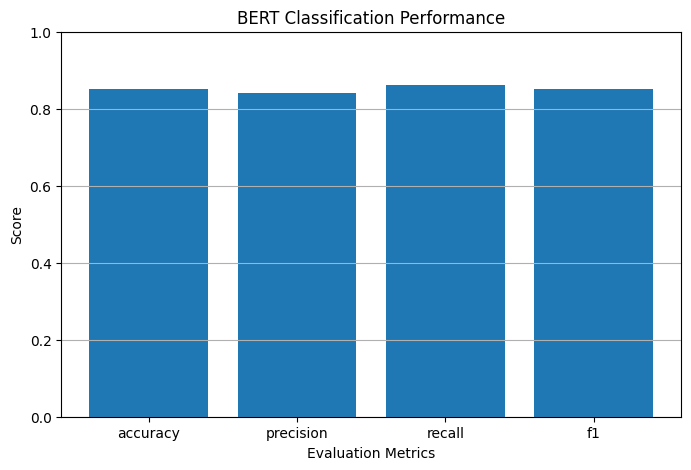

In [29]:
metrics = compute_metrics((
    predictions_output.predictions,
    y_true
))

metric_names = list(metrics.keys())
metric_values = list(metrics.values())

plt.figure(figsize=(8, 5))

plt.bar(metric_names, metric_values)

plt.title("BERT Classification Performance")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")

plt.ylim(0, 1)
plt.grid(axis='y')

plt.show()

In [30]:
sentiment_model.save_pretrained("final_bert_model")

sentiment_tokenizer.save_pretrained("final_bert_model")

t5_model.save_pretrained("final_t5_model")

t5_tokenizer.save_pretrained("final_t5_model")

print("All models saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

All models saved successfully!
